# Барное меню настоек

## 1. Задача

Разработать меню из 10 настоек на основе отзывов баров Санкт-Петербурга. Рассчитать необходимые закупки, сырьевую себестоимость и потенциальную выручку за два вечера работы бара.

## 2. Данные

Для исследования собраны отзывы гостей и информация об ассортименте заведений. Исходные данные находятся в [Excel-файле](technical/data/nastoyki_reviews.xlsx), результаты анализа — в [сводной таблице](technical/data/flavor_summary.csv). Для экономических расчётов используются две таблицы: [себестоимость напитков](technical/data/menu_economics.csv) и [общая закупка ингредиентов](technical/data/menu_raw_material_costs.csv).

In [1]:
from decimal import Decimal as D
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from technical.scripts.portfolio import ROOT, read_csv, research_summary, economics_summary, number, fmt, INK, PAPER

stats = research_summary()
menu = read_csv("data/menu_economics.csv")
purchases = read_csv("data/menu_raw_material_costs.csv")
flavors = pd.read_csv(ROOT / "data/flavor_summary.csv", encoding="utf-8-sig")
summary = economics_summary()
def show(headers, rows):
    text = "| "+" | ".join(headers)+" |\n| "+" | ".join(["---"]*len(headers))+" |\n"
    text += "\n".join("| "+" | ".join(str(v).replace("|"," / ") for v in row)+" |" for row in rows)
    display(Markdown(text))
show(["Показатель", "Количество"], [
    ["Собрано публикаций", stats["reviews_total"]],
    ["Проверено публикаций", stats["reviews_verified"]],
    ["Отзывов с конкретными вкусами", stats["concrete_reviews"]],
    ["Упоминаний вкусов", stats["concrete_mentions"]],
])

| Показатель | Количество |
| --- | --- |
| Собрано публикаций | 368 |
| Проверено публикаций | 358 |
| Отзывов с конкретными вкусами | 108 |
| Упоминаний вкусов | 198 |

## 3. Подготовка данных

Проверены источники отзывов. Названия одинаковых вкусов приведены к одному виду, а сочетания учитывались отдельно. Положительной оценкой считался только отзыв с явной похвалой конкретной настойки.

## 4. Анализ вкусов

Сравниваю, как часто выбранные вкусы упоминаются в отзывах и в скольких заведениях они встречаются. Это поможет оценить результаты исследования, но не покажет фактические продажи настоек.

| Вкус | Упоминания | Отзывы | Заведения | Положительные оценки |
| --- | --- | --- | --- | --- |
| Хреновуха | 7 | 7 | 6 | 5 |
| Вишня | 4 | 4 | 4 | 3 |
| Малина | 6 | 6 | 3 | 4 |
| Лимончелло | 4 | 4 | 4 | 4 |
| Щавель | 7 | 7 | 3 | 5 |
| Яблоко — базилик | 3 | 3 | 1 | 3 |
| Облепиха | 3 | 3 | 3 | 1 |
| Клюква | 3 | 3 | 2 | 0 |
| Халва | 6 | 6 | 3 | 5 |
| Малина — сливки | 2 | 2 | 1 | 2 |

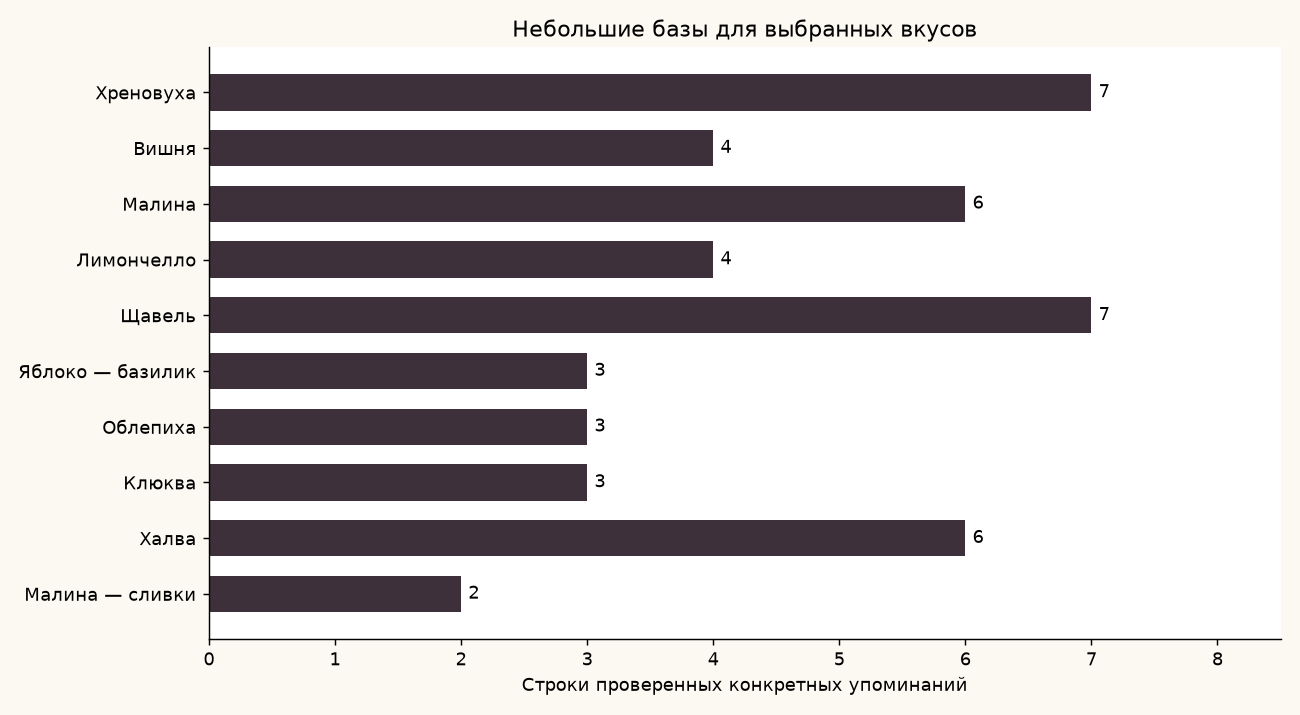

In [2]:
selected = flavors.set_index("Вкус").loc[[r["normalized_flavor"] for r in menu]]
show(["Вкус", "Упоминания", "Отзывы", "Заведения", "Положительные оценки"], [
    [name, int(row["Проверенные упоминания"]), int(row["Уникальные отзывы"]), int(row["Заведения"]), int(row["Положительные"])]
    for name, row in selected.iterrows()
])
with plt.rc_context({"font.family":"DejaVu Sans"}):
    fig, ax = plt.subplots(figsize=(10,5.5), facecolor=PAPER)
    values = selected["Проверенные упоминания"]
    bars = ax.barh(selected.index, values, color=INK, height=.65)
    ax.bar_label(bars, padding=4)
    ax.invert_yaxis(); ax.set(xlabel="Строки проверенных конкретных упоминаний", title="Небольшие базы для выбранных вкусов", xlim=(0,values.max()+1.5))
    ax.spines[["top","right"]].set_visible(False)
    from io import BytesIO
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=130, facecolor=PAPER)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

## 5. Формирование меню

По результатам исследования выбраны 10 настоек. Цены составляют 250 и 300 рублей за 50 мл в зависимости от сложности настойки.

## 6. Готовое меню

Настойки разделены по вкусовым категориям: сладкие, кислые, травяные и острые. Для каждого напитка указаны ингредиенты и цена за 50 мл.

[Открыть PDF](technical/results/nastoyka_menu.pdf)  [Изображение](technical/results/menu_preview.png)

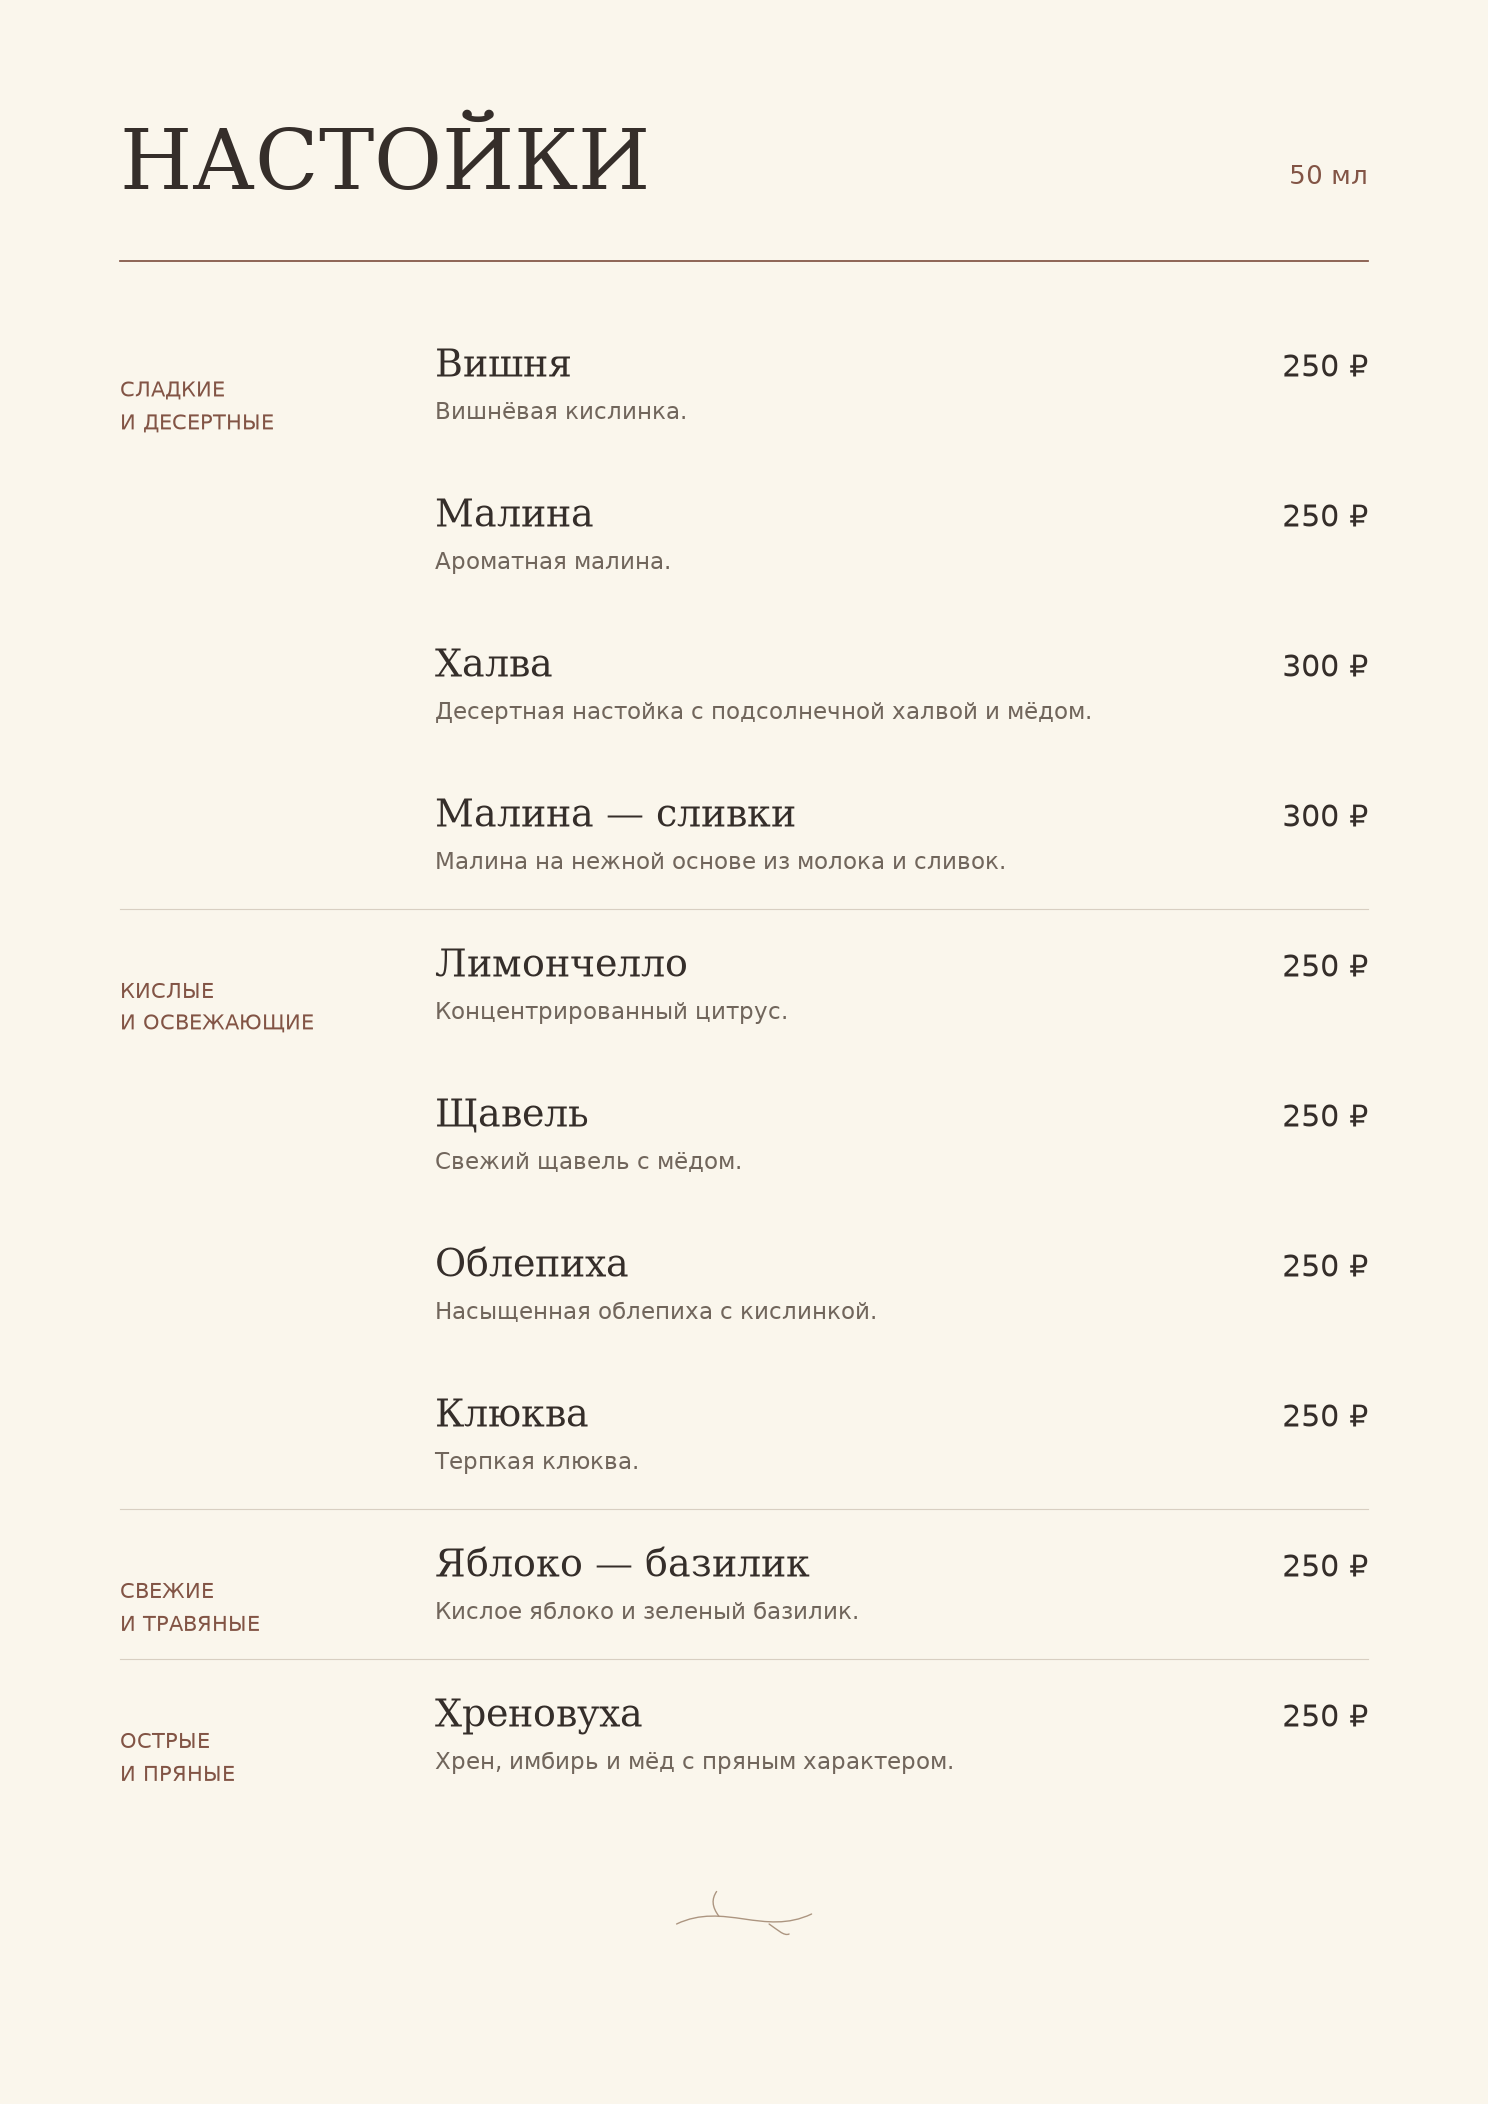

In [3]:
display(Image(filename=str(ROOT / "results/menu_preview.png"), width=650))

## 7. Закупка ингредиентов

Для каждого из 10 напитков запланировано по 6 литров. Общий объём составляет 60 литров, или 1 200 порций по 50 мл.

В таблице рассчитаны необходимые количества ингредиентов, стоимость закупки и остатки по сырью.

In [4]:
show(["Сырьё", "Нужно", "Ед.", "Заказ, ₽"], [
    [r["Сырьё"], r["Плановая потребность"], r["Единица"], r["Закупка, ₽"]]
    for r in purchases
])
supplier_totals = {}
for row in purchases:
    supplier_totals[row["Поставщик"]] = supplier_totals.get(row["Поставщик"], D(0)) + number(row["Закупка, ₽"])
show(["Поставщик", "Первая закупка, ₽"], [[name,fmt(value)] for name,value in supplier_totals.items()])

| Сырьё | Нужно | Ед. | Заказ, ₽ |
| --- | --- | --- | --- |
| Водка Царская Оригинальная 40% | 47,301 | л | 18 240,00 |
| Вишня замороженная без косточек | 2,174 | кг | 2 397,00 |
| Малина замороженная | 5,218 | кг | 5 994,00 |
| Облепиха замороженная | 4,167 | кг | 1 995,00 |
| Клюква замороженная | 3,582 | кг | 2 076,00 |
| Лимоны целые | 7,600 | кг | 1 432,00 |
| Щавель свежий | 1,132 | кг | 1 668,00 |
| Базилик зелёный свежий | 0,138 | кг | 447,00 |
| Сахар | 9,711 | кг | 729,00 |
| Мёд | 2,460 | кг | 987,00 |
| Халва подсолнечная | 8,000 | кг | 1 500,80 |
| Сливки 10% | 1,286 | л | 398,00 |
| Молоко 3.2% | 1,286 | л | 158,00 |
| Хрен: свежий необработанный корень | 1,213 | кг | 1 306,00 |
| Имбирь свежий | 0,191 | кг | 330,00 |
| Яблоки зелёные свежие | 4,846 | кг | 345,00 |

| Поставщик | Первая закупка, ₽ |
| --- | --- |
| Ладога | 18 240,00 |
| METRO | 19 781,80 |
| Агропарк СПб | 1 981,00 |

[Полная таблица закупок](technical/data/menu_raw_material_costs.csv) содержит фасовки, цены поставщиков и остатки по сырью.

## 8. Экономика меню

Для каждой настойки рассчитана стоимость сырья на 50 мл и на 6 литров. Результаты представлены в таблице и на графике.

| Настойка | Цена 50 мл, ₽ | Сырьё 50 мл, ₽ | Сырьё 6 л, ₽ |
| --- | --- | --- | --- |
| Хреновуха | 250,00 | 27,69 | 3 322,66 |
| Вишня | 250,00 | 29,56 | 3 547,61 |
| Малина | 250,00 | 37,08 | 4 449,53 |
| Лимончелло | 250,00 | 25,22 | 3 026,20 |
| Щавель | 250,00 | 34,14 | 4 096,98 |
| Яблоко — базилик | 250,00 | 21,29 | 2 554,68 |
| Облепиха | 250,00 | 27,55 | 3 306,58 |
| Клюква | 250,00 | 30,49 | 3 658,52 |
| Халва | 300,00 | 36,91 | 4 428,93 |
| Малина — сливки | 300,00 | 33,05 | 3 965,91 |

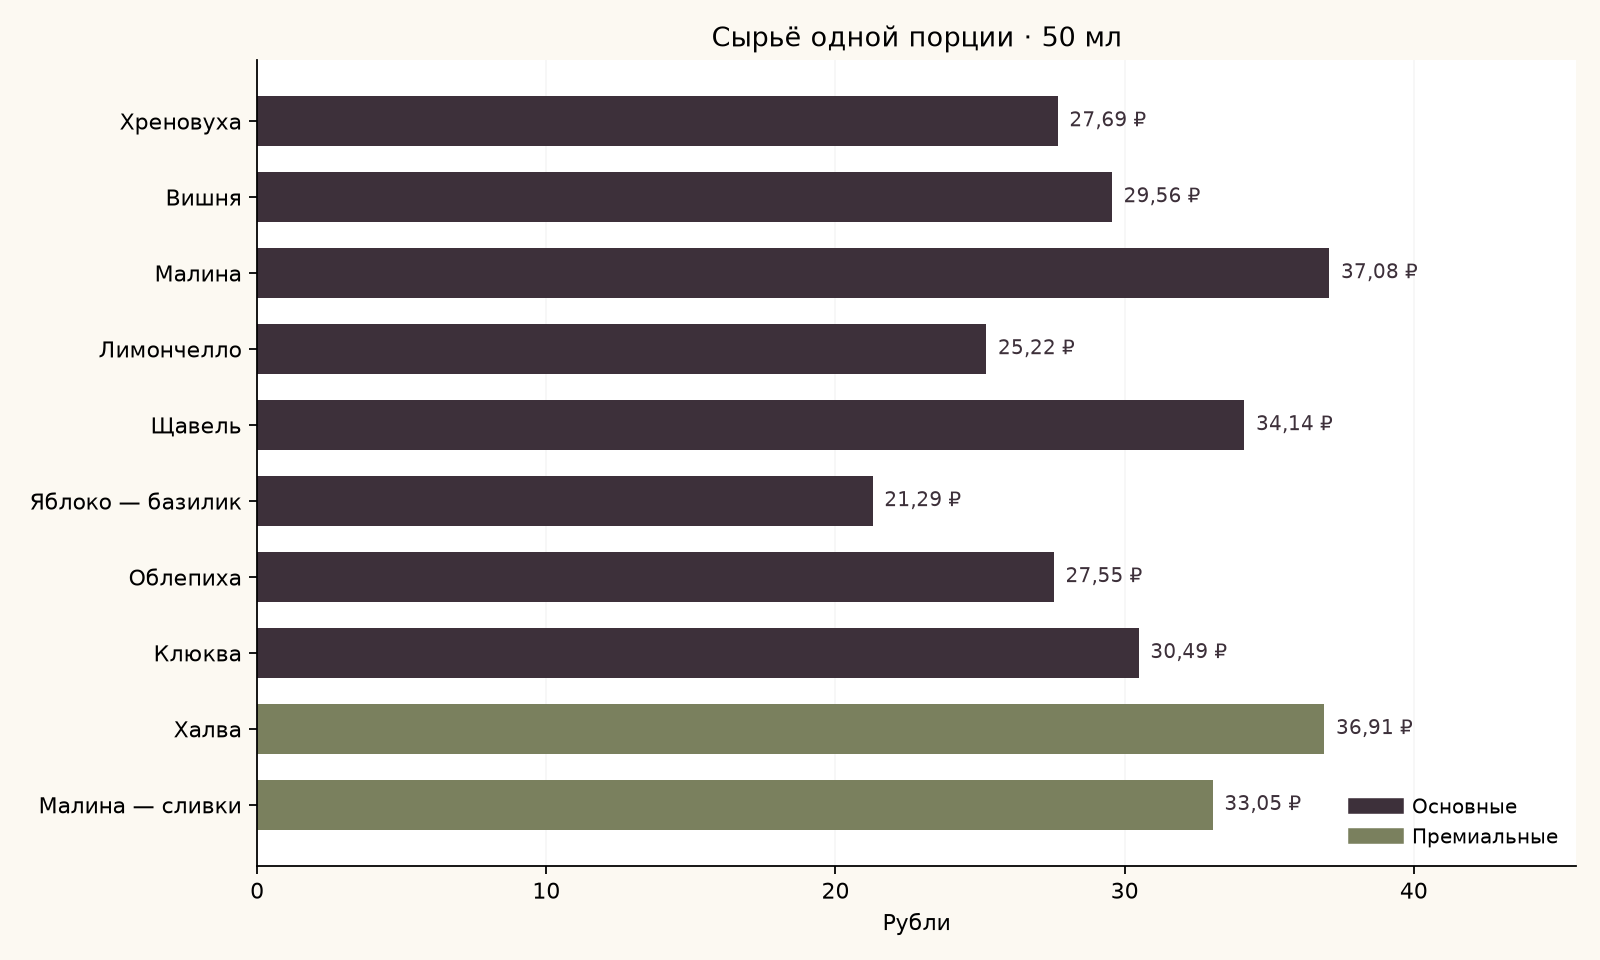

In [5]:
show(["Настойка", "Цена 50 мл, ₽", "Сырьё 50 мл, ₽", "Сырьё 6 л, ₽"], [
    [r["normalized_flavor"],fmt(r["price_50ml_rub"]),fmt(r["cost_50ml_rub"]),fmt(r["used_cost_rub"])]
    for r in menu
])
display(Image(filename=str(ROOT / "results/cost_50ml.png")))

### Сценарий полной реализации

In [6]:
show(["Показатель", "Сумма"], [
    ["Первоначальная закупка", fmt(summary["purchase_rub"])+" ₽"],
    ["Стоимость использованного сырья", fmt(summary["used_rub"])+" ₽"],
    ["Остаток сырья", fmt(summary["leftover_rub"])+" ₽"],
    ["Потенциальная выручка", fmt(summary["revenue_rub"], 0)+" ₽"],
])

| Показатель | Сумма |
| --- | --- |
| Первоначальная закупка | 40 002,80 ₽ |
| Стоимость использованного сырья | 36 357,61 ₽ |
| Остаток сырья | 3 645,19 ₽ |
| Потенциальная выручка | 312 000 ₽ |

## 9. Итоги

Разработано меню и подготовлена смета закупок для производства 60 литров.

Расчёты основаны на плановых объёмах и ценах.